# 02 — Planned kilometres: raw audit and first incident rates

**Goal.** Incident counts go up when more trains run. To separate *reliability* from
*service volume* we need an exposure measure, and the only one provided is planned
train-kilometres. This notebook

1. audits the planned-km file the same way notebook 01 audited the incidents
   (structure, placeholders, types, calendar, coverage), and
2. joins it to train incidents to get a first look at **incidents per million km**
   by line and month.

As in notebook 01, nothing here changes the data on disk. The incident parsing in
part 2 is deliberately minimal; the proper version belongs in `code/cleaning/`.

Source documentation: Ville de Montréal open-data page *Kilométrage métro des périodes
de service* (PDF copy shipped with the challenge).

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# The notebook lives in code/exploration/; config.py lives in code/.
sys.path.insert(0, str(Path.cwd().parent))
import config

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

# Same line order and colours as notebook 01.
MAIN_LINES = ["Ligne verte", "Ligne orange", "Ligne jaune", "Ligne bleue"]
LINE_COLORS = {"Ligne verte": "green", "Ligne orange": "orange",
               "Ligne jaune": "gold", "Ligne bleue": "blue"}

# Part 1 — Audit of the planned-km file

## 1. Load the raw file

Unlike the incidents file, this one is `,`-separated with no byte-order mark. Numbers
use a **decimal comma** (`"16315,92"`) and are quoted so they don't clash with the
separator. We read everything as text first, as in notebook 01.

In [2]:
km_raw = pd.read_csv(config.KM_RAW, dtype=str, keep_default_na=False)
print(f"{km_raw.shape[0]:,} rows x {km_raw.shape[1]} columns")
km_raw.head()

8,472 rows x 11 columns


,Ligne,Période Exploitation,Type de Jour,Tournée,Année civile,Année civile/mois,Année civile/semaine,Jour calendaire,Jour de la semaine,Mois calendrier,KM planifié
0,Ligne bleue,18N,Dimanche,001,2019,2019-01,2018-12-31,2019-01-06,Dimanche,1,15810
1,Ligne bleue,18N,Quatrième pér. fête,001,2019,2019-01,2018-12-31,2019-01-02,Mercredi,1,15810
2,Ligne bleue,18N,Samedi,001,2019,2019-01,2018-12-31,2019-01-05,Samedi,1,"16315,92"
3,Ligne bleue,18N,Semaine,001,2019,2019-01,2018-12-31,2019-01-03,Jeudi,1,"26940,24"
4,Ligne bleue,18N,Semaine,001,2019,2019-01,2018-12-31,2019-01-04,Vendredi,1,"26940,24"


## 2. Data dictionary

In [3]:
km_dictionary = pd.DataFrame(
    [
        ("Ligne",                "Metro line"),
        ("Période Exploitation", "Service period ('liste'): year + letter, e.g. 19J"),
        ("Type de Jour",         "Day type: weekday / Saturday / Sunday / holiday tiers"),
        ("Tournée",              "Train run number the km are attached to"),
        ("Année civile",         "Year"),
        ("Année civile/mois",    "Year-month (YYYY-MM)"),
        ("Année civile/semaine", "Week, labelled by its Monday (YYYY-MM-DD)"),
        ("Jour calendaire",      "Calendar date"),
        ("Jour de la semaine",   "Weekday name in French"),
        ("Mois calendrier",      "Month number"),
        ("KM planifié",          "Planned train-km after budget adjustments"),
    ],
    columns=["column", "meaning"],
)
assert list(km_dictionary["column"]) == list(km_raw.columns)
km_dictionary

,column,meaning
0,Ligne,Metro line
1,Période Exploitation,"Service period ('liste'): year + letter, e.g. 19J"
2,Type de Jour,Day type: weekday / Saturday / Sunday / holida...
3,Tournée,Train run number the km are attached to
4,Année civile,Year
5,Année civile/mois,Year-month (YYYY-MM)
6,Année civile/semaine,"Week, labelled by its Monday (YYYY-MM-DD)"
7,Jour calendaire,Calendar date
8,Jour de la semaine,Weekday name in French
9,Mois calendrier,Month number


## 3. Distinct values per column

A quick look at cardinality shows which columns carry information and which are
constant.

In [4]:
summary = pd.DataFrame({
    "distinct": km_raw.nunique(),
    "most common": km_raw.apply(lambda col: col.value_counts().index[0]),
    "top share %": km_raw.apply(lambda col: round(100 * col.value_counts(normalize=True).iloc[0], 1)),
})
summary

,distinct,most common,top share %
Ligne,4,Ligne bleue,25.0
Période Exploitation,28,#,18.1
Type de Jour,8,Semaine,56.5
Tournée,1,001,100.0
Année civile,5,2019,34.5
Année civile/mois,57,2019-01,2.9
Année civile/semaine,248,2019-01-07,0.7
Jour calendaire,1734,2019-01-06,0.1
Jour de la semaine,7,Mercredi,14.3
Mois calendrier,12,6,9.2


* `Tournée` is always `001`, although the documentation lists five values
  (001, 050, 060, 066, 999). The published extract seems to contain only one run
  category, so we cannot tell what share of total km it represents.
* `Ligne` has only the four main lines: there is no km for multi-line or
  unassigned incidents to be matched against.

## 4. Type check: the km column

Convert the decimal comma to a point and check that every value parses.

In [5]:
km_raw["km"] = pd.to_numeric(km_raw["KM planifié"].str.replace(",", ".", regex=False),
                             errors="coerce")
print(f"Values that fail to parse: {km_raw['km'].isna().sum()}")
print(f"Negative values:           {(km_raw['km'] < 0).sum()}")
print(f"Zero values:               {(km_raw['km'] == 0).sum():,}")
km_raw["km"].describe().round(1).to_frame()

Values that fail to parse: 0
Negative values:           0
Zero values:               1,536


,km
count,8472.0
mean,48171.5
std,46703.6
min,0.0
25%,13338.4
50%,24284.2
75%,89999.7
max,141617.5


Everything parses, but there are many zeros. That is suspicious for a metro that runs
every day. The next section explains them.

## 5. Placeholder rows and the grain of the table

The documentation says km is split by line, day, service period and run. So we expect
**one row per line per day**. Let's check.

In [6]:
km_raw["date"] = pd.to_datetime(km_raw["Jour calendaire"], format="%Y-%m-%d")

rows_per_line_day = km_raw.groupby(["Ligne", "date"]).size()
print("Rows per (line, day):")
print(rows_per_line_day.value_counts().to_string())

# Placeholder rows: period '#' and day type 'Non affecté' ("not assigned").
km_raw["placeholder"] = km_raw["Période Exploitation"].eq("#")
print("\nPlaceholder rows always have day type 'Non affecté':",
      km_raw.loc[km_raw["placeholder"], "Type de Jour"].eq("Non affecté").all())

Rows per (line, day):
1    5400
2    1536

Placeholder rows always have day type 'Non affecté': True


In [7]:
# For the (line, day) pairs that have two rows: how many of the two carry km > 0?
nonzero_per_line_day = (km_raw.assign(nonzero=km_raw["km"] > 0)
                        .groupby(["Ligne", "date"])["nonzero"].sum())
print("Number of rows with km > 0, per (line, day):")
print(nonzero_per_line_day.value_counts().to_string())

Number of rows with km > 0, per (line, day):
nonzero
1    6936


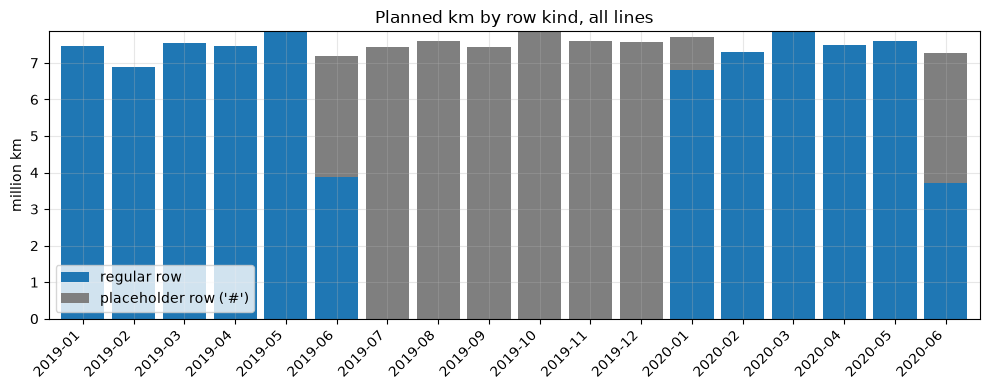

In [8]:
# Plot: where does the km sit, regular row or placeholder row? (2019 to mid-2020 only,
# the period when placeholder rows exist.)
early = km_raw[km_raw["date"] < "2020-07-01"]
by_kind = (early.groupby([early["date"].dt.to_period("M"), "placeholder"])["km"].sum()
           .unstack(fill_value=0) / 1e6)
by_kind.columns = ["regular row", "placeholder row ('#')"]

fig, ax = plt.subplots()
by_kind.plot.bar(ax=ax, stacked=True, color=["tab:blue", "tab:gray"], width=0.85)
ax.set_title("Planned km by row kind, all lines")
ax.set_xlabel("")
ax.set_ylabel("million km")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Finding.** Every line-day of 2019, plus 1–5 January 2020 and 1–14 June 2020, has a
second, placeholder row. Exactly **one** of the two rows holds the km; the other holds 0.
For the service periods starting 17 June 2019 (`19U`, `19S`, `19N`) and for the short
`20C` period, the km sits on the *placeholder* row and the regular row is zero.
Someone summing only the "valid-looking" rows would lose over half of 2019.

**Rule for cleaning:** sum all rows per (line, day). That gives one correct daily km
value whichever row carries it. The period and day-type labels then have to be taken
from the regular row.

## 6. Calendar consistency

The km file repeats the date several times (year, month, week, weekday). Check they
agree with `Jour calendaire`.

In [9]:
WEEKDAY_FR = {"Lundi": 0, "Mardi": 1, "Mercredi": 2, "Jeudi": 3,
              "Vendredi": 4, "Samedi": 5, "Dimanche": 6}
date = km_raw["date"]

# The week column should be the Monday of the week containing the date.
week_monday = date - pd.to_timedelta(date.dt.dayofweek, unit="D")

km_checks = pd.DataFrame({
    "year matches":       km_raw["Année civile"].astype(int) == date.dt.year,
    "year-month matches": km_raw["Année civile/mois"] == date.dt.strftime("%Y-%m"),
    "month matches":      km_raw["Mois calendrier"].astype(int) == date.dt.month,
    "weekday matches":    km_raw["Jour de la semaine"].map(WEEKDAY_FR) == date.dt.dayofweek,
    "week = its Monday":  pd.to_datetime(km_raw["Année civile/semaine"]) == week_monday,
})
(100 * (1 - km_checks.mean())).round(2).rename("% mismatching").to_frame()

,% mismatching
year matches,0.0
year-month matches,0.0
month matches,0.0
weekday matches,0.0
week = its Monday,0.0


In [10]:
# Day type vs actual weekday (regular rows only; placeholders have no day type).
regular = km_raw[~km_raw["placeholder"]]
pd.crosstab(regular["Type de Jour"], regular["Jour de la semaine"])[list(WEEKDAY_FR)]

Jour de la semaine,Lundi,Mardi,Mercredi,Jeudi,Vendredi,Samedi,Dimanche
Type de Jour,,,,,,,
Deuxième pér. fête,44,0,4,8,4,8,4
Dimanche,0,0,0,0,0,0,972
Premième pér. fête,24,0,8,4,28,8,4
Quatrième pér. fête,4,0,4,4,0,4,4
Samedi,0,0,0,0,0,968,0
Semaine,896,988,972,976,956,0,0
Troisième pér. fête,20,4,4,0,4,4,4


In [11]:
# Which dates are tagged as holidays ("pér. fête" = holiday period, tiers 1 to 4)?
holidays = (regular.loc[regular["Type de Jour"].str.contains("fête"), ["date", "Type de Jour"]]
            .drop_duplicates("date").sort_values("date"))
holidays[holidays["date"].dt.year == 2019]

,date,Type de Jour
5,2019-01-01,Troisième pér. fête
1,2019-01-02,Quatrième pér. fête
96,2019-04-19,Premième pér. fête
83,2019-04-22,Deuxième pér. fête
166,2019-05-20,Troisième pér. fête
311,2019-06-24,Premième pér. fête
300,2019-07-01,Deuxième pér. fête
247,2019-09-02,Premième pér. fête
237,2019-10-14,Deuxième pér. fête
178,2019-12-25,Premième pér. fête


**Findings.** Every date field agrees with `Jour calendaire`. Day types match the
weekday, except for holidays, which are typed by tier (`Premième` is a misspelling of
`Première`, "first") and fall on the expected Québec statutory holidays (New Year,
Good Friday / Easter Monday, Victoria Day, Saint-Jean, Canada Day, Labour Day,
Thanksgiving, Christmas). The holiday tag is a ready-made **holiday feature** we can
reuse for incidents.

## 7. Coverage

Compare the time window with the incidents file and check for missing days.

In [12]:
first_day, last_day = km_raw["date"].min(), km_raw["date"].max()
print(f"Planned km covers: {first_day.date()} to {last_day.date()}")

all_days = pd.date_range(first_day, last_day, freq="D")
for line, group in km_raw.groupby("Ligne"):
    missing_days = all_days.difference(group["date"])
    print(f"  {line:13s} missing days: {len(missing_days)}")

Planned km covers: 2019-01-01 to 2023-09-30
  Ligne bleue   missing days: 0
  Ligne jaune   missing days: 0
  Ligne orange  missing days: 0
  Ligne verte   missing days: 0


**Finding: the most important limitation of this file.** Planned km stops on
**2023-09-30**, while incidents run to **2025-09-30**. Exposure is therefore missing
for the last two years of incidents. Any rate (incidents per km) can only be computed
for 2019-01 to 2023-09. Within that window there are no gaps.

## 8. Service periods

The documentation says the year is split into five service periods ("listes"):
January, March, June, September, November.

In [13]:
periods = (regular.groupby("Période Exploitation")["date"]
           .agg(start="min", end="max", days="nunique")
           .sort_values("start"))
periods

,start,end,days
Période Exploitation,,,
18N,2019-01-01,2019-01-06,6
19J,2019-01-07,2019-03-24,77
19M,2019-03-25,2019-06-16,84
19U,2019-06-17,2019-08-25,70
19S,2019-08-26,2019-10-27,63
19N,2019-10-28,2020-01-05,70
20J,2020-01-06,2020-03-22,77
20M,2020-03-23,2020-05-31,70
20C,2020-06-01,2020-06-14,14


The codes read as *year + letter*: **J**anvier, **M**ars, s**U**mmer (juin),
**S**eptembre, **N**ovembre. Two short 2-week periods (`20C`, `21MV`) sit between
spring and summer, and from 2021 the codes gain a `B` or `V` suffix (not documented).
Periods change on Mondays, so the km schedule is piecewise constant.

## 9. Planned km over time

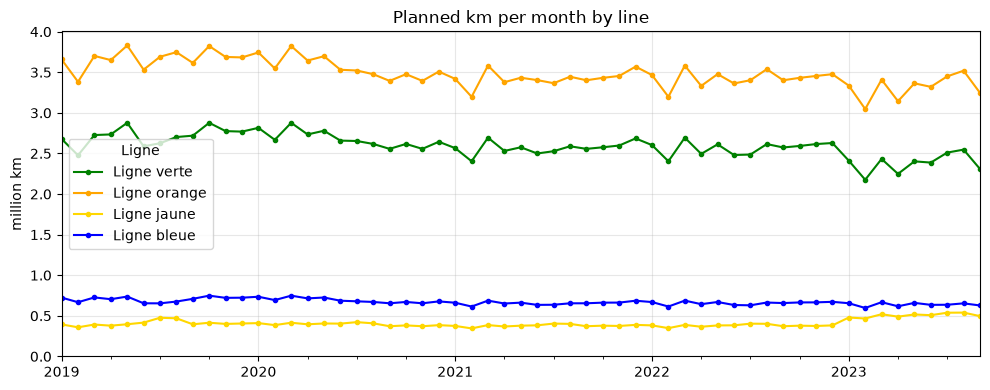

In [14]:
# One clean row per (line, day): sum the regular and placeholder rows (section 5).
daily_km = (km_raw.groupby(["date", "Ligne"])["km"].sum()
            .unstack()[MAIN_LINES])

# Plot: monthly planned km by line.
monthly_km = daily_km.resample("MS").sum() / 1e6

fig, ax = plt.subplots()
monthly_km.plot(ax=ax, color=LINE_COLORS, marker=".")
ax.set_title("Planned km per month by line")
ax.set_xlabel("")
ax.set_ylabel("million km")
ax.set_ylim(0, None)
plt.tight_layout()
plt.show()

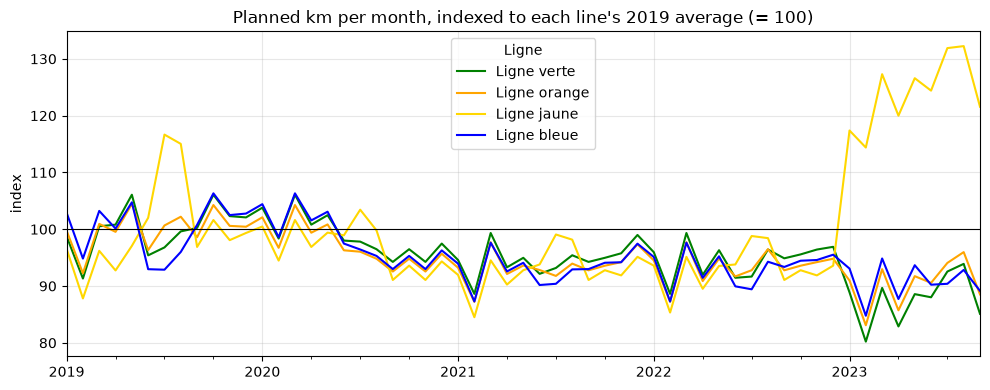

In [15]:
# Plot: the same series relative to each line's 2019 monthly average, to compare
# lines of very different size on one scale.
index_2019 = 100 * monthly_km / monthly_km.loc["2019"].mean()

fig, ax = plt.subplots()
index_2019.plot(ax=ax, color=LINE_COLORS)
ax.axhline(100, color="black", linewidth=0.8)
ax.set_title("Planned km per month, indexed to each line's 2019 average (= 100)")
ax.set_xlabel("")
ax.set_ylabel("index")
plt.tight_layout()
plt.show()

**Findings.**
* **COVID barely shows.** Ridership collapsed from March 2020, but planned km dipped
  only a few percent. This is *planned* service, not service actually run, so it can
  miss cancellations, strikes and shutdowns.
* **Yellow line level shift.** Planned km on the yellow line jumps by roughly 20-30% in
  January 2023 and stays there, while the other lines drift slightly down. This could
  be a real service change or a change in how km is allocated; the data alone cannot
  tell. Any yellow-line rate across 2022 → 2023 must be read with that in mind.
* Inside each month the pattern is very regular (weekday vs weekend schedules), which
  is why monthly sums are smooth.

# Part 2 — First incident rates

## 10. Train incidents per line and month

Minimal parsing of the incidents file, reusing what notebook 01 established:
* train incidents only (`Type d'incident == "T"`)
* the four main lines only (km exists only for those)
* month taken from the **service-day** fields (`Année civile`, `Mois calendrier`)
* `>= 5 min` as the working definition of service-affecting (industry convention cited
  in the documentation; the real target is chosen later)

In [16]:
incidents = pd.read_csv(config.INCIDENTS_RAW, sep=";", encoding="utf-8-sig",
                        dtype=str, keep_default_na=False)

BUCKETS = ["02 min et moins", "03 à 04 min", "05 à 09 min", "10 à 14 min",
           "15 à 19 min", "20 à 24 min", "25 à 29 min", "30 min et plus"]

train = incidents[(incidents["Type d'incident"] == "T")
                  & incidents["Ligne"].isin(MAIN_LINES)].copy()
train["month"] = pd.to_datetime(dict(year=train["Année civile"].astype(int),
                                     month=train["Mois calendrier"].astype(int),
                                     day=1))
bucket = pd.Categorical(train["Incident en minutes"], categories=BUCKETS, ordered=True)
train["delay_5plus"] = bucket >= "05 à 09 min"

# Count incidents per line-month: all train incidents, and the >= 5 min subset.
counts_all = train.groupby(["month", "Ligne"]).size().unstack(fill_value=0)[MAIN_LINES]
counts_5 = (train[train["delay_5plus"]].groupby(["month", "Ligne"]).size()
            .unstack(fill_value=0)[MAIN_LINES])

dropped = (incidents["Type d'incident"] == "T").sum() - len(train)
print(f"Train incidents on the four main lines: {len(train):,} "
      f"({dropped} multi-line / unassigned train incidents left out)")

Train incidents on the four main lines: 28,718 (449 multi-line / unassigned train incidents left out)


## 11. Rates per million km

Restrict to the window where both files overlap and divide.

In [17]:
# Overlap window: months with planned km (the km file ends 2023-09).
overlap = monthly_km.index
km_m = monthly_km.loc[overlap]                     # million km
rate_all = counts_all.reindex(overlap, fill_value=0) / km_m
rate_5 = counts_5.reindex(overlap, fill_value=0) / km_m

print(f"Overlap window: {overlap.min():%Y-%m} to {overlap.max():%Y-%m} ({len(overlap)} months)")

Overlap window: 2019-01 to 2023-09 (57 months)


In [18]:
# Table: each line's share of planned km vs its share of incidents, over the overlap.
# If incidents simply scaled with service, the shares would be equal.
window = slice(overlap.min(), overlap.max())
shares = pd.DataFrame({
    "% of planned km":         100 * km_m.sum() / km_m.sum().sum(),
    "% of train incidents":    100 * counts_all.loc[window].sum() / counts_all.loc[window].sum().sum(),
    "% of >= 5 min incidents": 100 * counts_5.loc[window].sum() / counts_5.loc[window].sum().sum(),
    ">= 5 min per million km": counts_5.loc[window].sum() / km_m.sum(),
}).round(1)
shares

,% of planned km,% of train incidents,% of >= 5 min incidents,>= 5 min per million km
Ligne,,,,
Ligne verte,36.2,41.9,45.1,12.8
Ligne orange,48.7,40.2,38.9,8.2
Ligne jaune,5.7,6.6,5.1,9.1
Ligne bleue,9.4,11.2,11.0,12.1


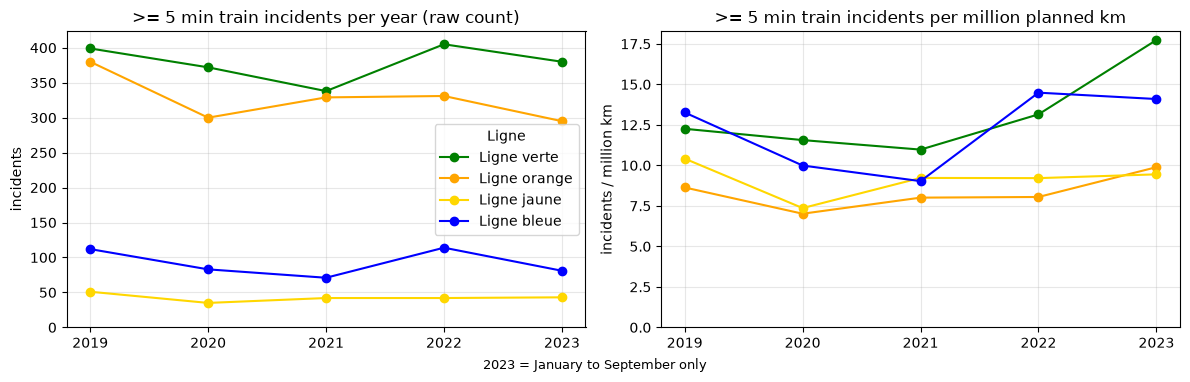

In [19]:
# Plot: raw counts vs rates per million km (>= 5 min incidents), yearly, by line.
# Yearly sums smooth the noise; 2023 covers January to September in both files.
yearly_count = counts_5.reindex(overlap, fill_value=0).groupby(overlap.year).sum()
yearly_km = km_m.groupby(overlap.year).sum()
yearly_rate = yearly_count / yearly_km

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
yearly_count.plot(ax=axes[0], marker="o", color=LINE_COLORS)
axes[0].set_title(">= 5 min train incidents per year (raw count)")
axes[0].set_ylabel("incidents")
yearly_rate.plot(ax=axes[1], marker="o", color=LINE_COLORS, legend=False)
axes[1].set_title(">= 5 min train incidents per million planned km")
axes[1].set_ylabel("incidents / million km")
for ax in axes:
    ax.set_xlabel("")
    ax.set_xticks(yearly_rate.index)  # whole years only on the axis
    ax.set_ylim(0, None)
fig.suptitle("2023 = January to September only", fontsize=9, y=0.02)
plt.tight_layout()
plt.show()

**Findings.**
* **Volume and reliability rank lines differently.** Orange runs about half of all
  planned km but has the *lowest* rate of >= 5 min incidents per km; green and blue have
  the highest. Raw counts would put orange near the top.
* **Green line is getting worse per km.** Its raw count is roughly flat, but planned km
  fell, so its rate rises from about 11 (2021) to about 18 (2023) per million km.
* **Yellow line:** the count stays flat while planned km jumps in 2023, so its rate
  barely moves. Given the km break in section 9, we cannot say if that is real.
* 2020 is low for every line, which fits reduced ridership (fewer customer-caused
  incidents) while *planned* km stayed high.

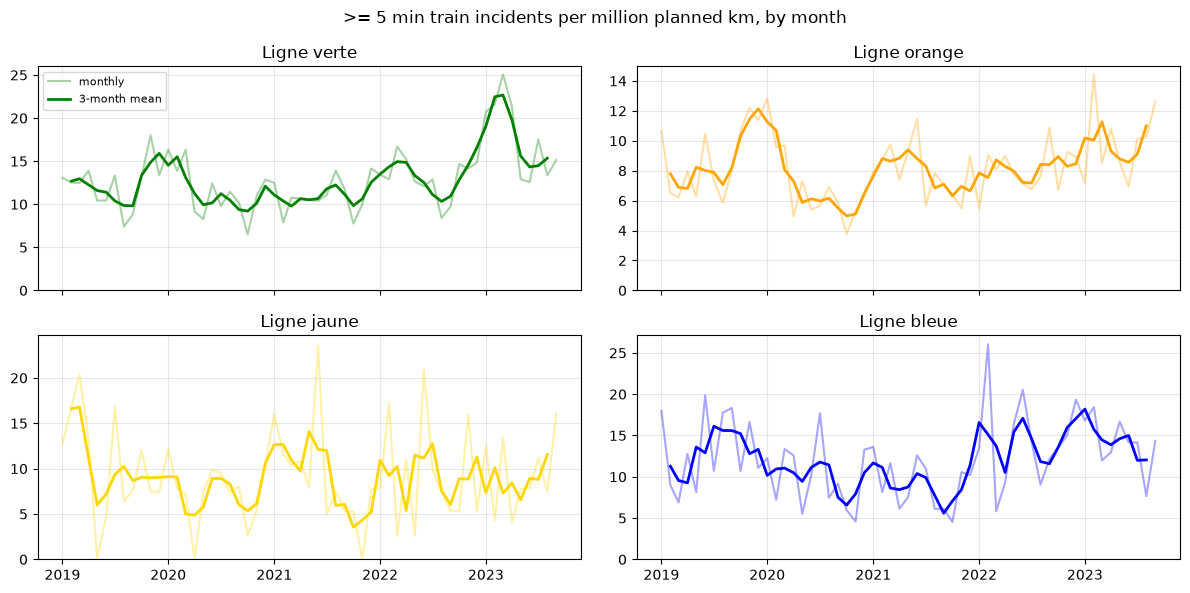

In [20]:
# Plot: monthly rate per line with a 3-month rolling mean, to see how noisy a
# line-month rate is. Small lines have few incidents per month, so their rate jumps.
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for ax, line in zip(axes.flat, MAIN_LINES):
    ax.plot(rate_5.index, rate_5[line], color=LINE_COLORS[line], alpha=0.35, label="monthly")
    ax.plot(rate_5.index, rate_5[line].rolling(3, center=True).mean(),
            color=LINE_COLORS[line], linewidth=2, label="3-month mean")
    ax.set_title(line)
    ax.set_ylim(0, None)
axes[0, 0].legend(fontsize=8)
fig.suptitle(">= 5 min train incidents per million planned km, by month")
plt.tight_layout()
plt.show()

In [21]:
# How many >= 5 min incidents does a typical line-month contain? This decides whether a
# line-month rate is precise enough to rank lines or months.
counts_5.loc[window].describe().round(1)

Ligne,Ligne verte,Ligne orange,Ligne jaune,Ligne bleue
count,57.0,57.0,57.0,57.0
mean,33.2,28.7,3.7,8.1
std,8.8,7.9,2.1,3.0
min,17.0,13.0,0.0,3.0
25%,27.0,23.0,2.0,6.0
50%,32.0,27.0,3.0,8.0
75%,38.0,34.0,5.0,10.0
max,61.0,48.0,9.0,16.0


The yellow line has a median of **3** service-affecting incidents per month and some
months with zero; the blue line about 8. Monthly rates for these lines are mostly
noise. Comparisons need longer windows or a count model with uncertainty.

## 12. To-do list from this notebook

| # | Issue | Proposed handling |
|---|---|---|
| 1 | Decimal comma in `KM planifié` | Parse with `,` → `.` |
| 2 | Placeholder rows (`#` / `Non affecté`) until mid-2020; km on *either* row | Sum all rows per (line, day); take period / day type from the regular row |
| 3 | Planned km ends 2023-09-30, incidents end 2025-09-30 | Rates only on 2019-01 → 2023-09; the incident-level model can still use all years, but cannot use km as a feature after 2023-09 |
| 4 | Planned, not delivered, km (COVID barely visible) | State as a limitation; exposure is approximate, especially in 2020 |
| 5 | Yellow line +~30% planned km from 2023-01 | Flag as a structural break; do not read the yellow 2022 → 2023 rate change as reliability |
| 6 | `Tournée` constant (`001`) | Drop; note the extract may not cover every run category |
| 7 | Only the four main lines have km | Multi-line / unassigned incidents have no exposure; keep them out of rates |
| 8 | Holiday tags by date | Reuse as a holiday feature for incidents |
| 9 | Small monthly counts on yellow / blue lines | Report rates on longer windows or with confidence intervals; a count model (Poisson / negative binomial with km offset) handles this properly |